# Notebook for cloud and rain drop radii
- Plot for Figure 3 (radii distribution)
- Cloud droplet radius with instantaneous values (Figure S1)

In [ ]:
ref_exp = "iconml_amip_2mom_reference_60s"
SDN_exp = "iconml_amip_superdropnet_sharma25_60s"
SDN_exp_1x60s = "iconml_amip_superdropnet_sharma25_60s_single_2ndtry"
DATA_DIR = "../data/"
grid_file = "iconml_amip_2mom_reference/icon_grid_0054_R02B08_G.nc"

In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sn
import numpy as np

In [ ]:

# Note the different dropping of time steps! 
dayslice= slice('2020-01-17', '2020-01-22T00:00:00.000000000')
heightslice = slice(50,90)


atm_3d_P1D_ref = xr.open_dataset(DATA_DIR + f"/{ref_exp}_atm_3d_P1D_3_moments_mergetime.nc").sel(time=dayslice).sel(height=heightslice)
atm_3d_P1D_SDN = xr.open_dataset(DATA_DIR + f"/{SDN_exp}_atm_3d_P1D_3_moments_mergetime.nc").sel(time=dayslice).sel(height=heightslice)
atm_3d_P1D_SDN_1x60 = xr.open_dataset(DATA_DIR + f"/{SDN_exp_1x60s}_atm_3d_P1D_3_moments_mergetime.nc").sel(time=dayslice).sel(height=heightslice)


In [4]:
clw_ref = xr.open_dataset(DATA_DIR + f"/{ref_exp}_atm_3d_P1D_2_hus_clw_cli_mergetime.nc").sel(time=dayslice).sel(height=heightslice).clw
clw_SDN = xr.open_dataset(DATA_DIR + f"/{SDN_exp}_atm_3d_P1D_2_hus_clw_cli_mergetime.nc").sel(time=dayslice).sel(height=heightslice).clw
clw_SDN_1x60 = xr.open_dataset(DATA_DIR + f"/{SDN_exp_1x60s}_atm_3d_P1D_2_hus_clw_cli_mergetime.nc").sel(time=dayslice).sel(height=heightslice).clw

In [ ]:
# Attach cell centre lat/lon (deg) from the ICON grid to select latitude bands on the unstructured grid
grid = xr.open_dataset(DATA_DIR + grid_file)

for ds in (atm_3d_P1D_ref, atm_3d_P1D_SDN, atm_3d_P1D_SDN_1x60):
    ds.coords["clat"] = ("ncells", grid.clat.values * 180. / np.pi)
    ds.coords["clon"] = ("ncells", grid.clon.values * 180. / np.pi)

In [6]:
rho_w = 1000.0  # kg/m^3, liquid water density

def mass_to_radius(mass):
    """Convert mean particle mass [kg] to radius [m], assuming spherical droplets."""
    return (3 * mass / (4 * np.pi * rho_w)) ** (1/3)

for ds, clw in ((atm_3d_P1D_ref, clw_ref),
                (atm_3d_P1D_SDN, clw_SDN),
                (atm_3d_P1D_SDN_1x60, clw_SDN_1x60)):
    ds["clw"] = clw
    # mean mass per particle, guarded against tiny number concentrations
    ds["qr/qnr"] = xr.where(ds.qnr > 10e2, ds.qr / ds.qnr, 0)
    ds["clw/qnc"] = xr.where(ds.qnc > 10e2, clw / ds.qnc, 0)
    # mean radius in micrometres
    ds["r_rain"] = mass_to_radius(ds["qr/qnr"]) * 1e6
    ds["r_cloud"] = mass_to_radius(ds["clw/qnc"]) * 1e6

atm_3d_P1D_SDN["r_rain"].attrs["long_name"] = "Daily Mean $r_r$ / $\mu m$"
atm_3d_P1D_SDN["r_cloud"].attrs["long_name"] = "Daily Mean $r_c$  / $\mu m$"

## Drop size probability density (native grid)

Global vs. tropics, selected on the unstructured grid via the `clat` cell-centre latitudes.

In [7]:
%%time
lat_bnd = 20

# clat is identical across datasets (same grid) -> get cell indices once with numpy
clat_deg = grid.clat.values * 180. / np.pi
trop_idx = np.nonzero((clat_deg > -lat_bnd) & (clat_deg < lat_bnd))[0]

def tropics(ds):
    """Select the |lat| < lat_bnd band by positional indexing (fast, lazy-friendly)."""
    return ds.isel(ncells=trop_idx)

atm_3d_P1D_ref_trop = tropics(atm_3d_P1D_ref)
atm_3d_P1D_SDN_1x60_trop = tropics(atm_3d_P1D_SDN_1x60)
atm_3d_P1D_SDN_trop = tropics(atm_3d_P1D_SDN)

CPU times: user 15.3 s, sys: 2.53 s, total: 17.8 s
Wall time: 18.1 s


CPU times: user 2min 21s, sys: 7.08 s, total: 2min 28s
Wall time: 2min 32s


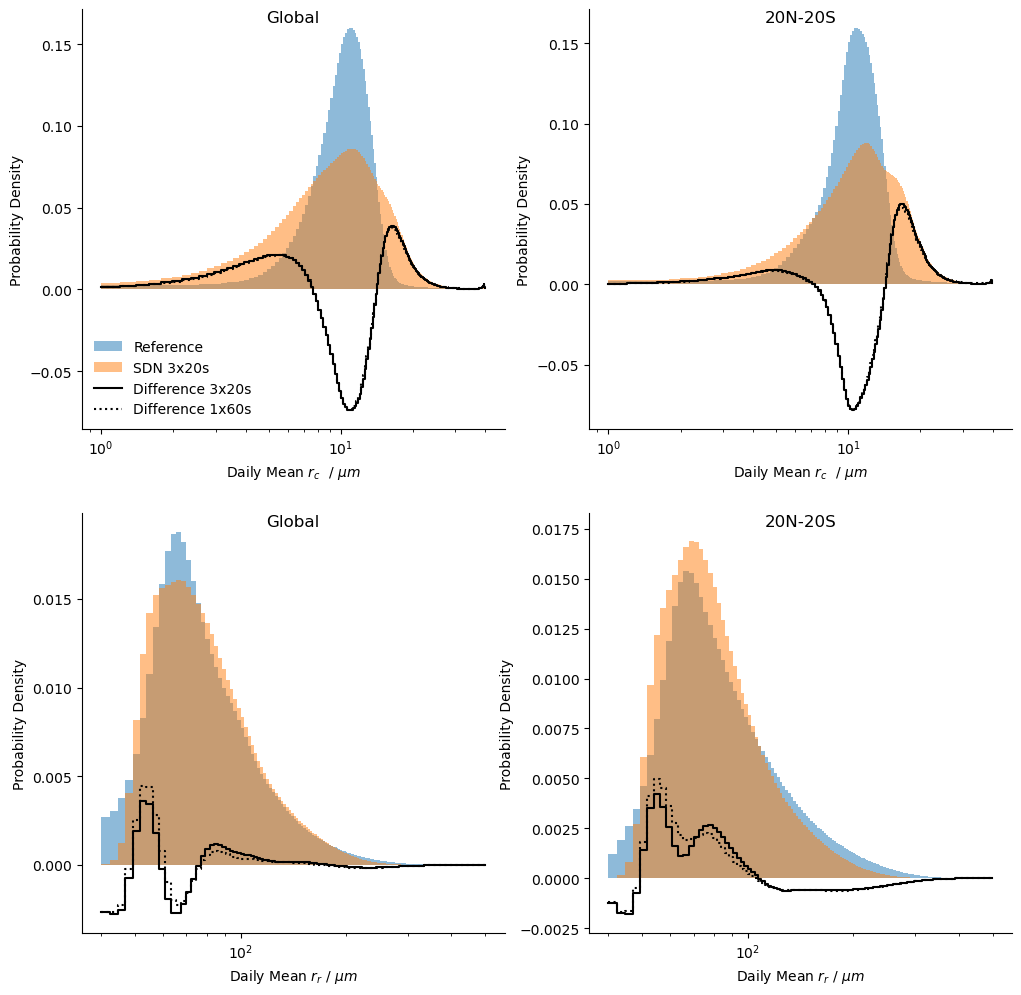

In [8]:
%%time

fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharey=False)
sn.despine(fig=fig)

data_vars_in_order = ["r_cloud", "r_rain"]
bins_global = [np.linspace(1, 40, 200), np.linspace(40, 500, 200)]

for i, var in enumerate(data_vars_in_order):
    # --- Global ---
    ax = axes[i, 0]
    histo_ref = atm_3d_P1D_ref[var].plot(ax=ax, alpha=0.5, label="Reference", bins=bins_global[i], density=True)
    histo_SDN_1x60 = atm_3d_P1D_SDN_1x60[var].plot(ax=ax, alpha=0, bins=histo_ref[1], density=True)
    histo_SDN = atm_3d_P1D_SDN[var].plot(ax=ax, alpha=0.5, bins=histo_ref[1], color="tab:orange", label="SDN 3x20s", density=True)
    histo_diff = histo_SDN[0] - histo_ref[0]
    histo_diff_1x60s = histo_SDN_1x60[0] - histo_ref[0]
    ax.step(histo_ref[1][:-1], histo_diff, color="black", label="Difference 3x20s", where='post')
    ax.step(histo_ref[1][:-1], histo_diff_1x60s, color="black", label="Difference 1x60s", where='post', linestyle=":")
    ax.set_xscale('log')
    ax.set_ylabel("Probability Density")
    ax.set_title("Global", x=0.5, y=0.95)

    # --- Tropics ---
    ax = axes[i, 1]
    histo_ref = atm_3d_P1D_ref_trop[var].plot(ax=ax, alpha=0.5, label="Reference", bins=bins_global[i], density=True)
    histo_SDN_1x60 = atm_3d_P1D_SDN_1x60_trop[var].plot(ax=ax, alpha=0, bins=histo_ref[1], density=True)
    histo_SDN = atm_3d_P1D_SDN_trop[var].plot(ax=ax, alpha=0.5, label="SDN", bins=histo_ref[1], color="tab:orange", density=True)
    histo_diff = histo_SDN[0] - histo_ref[0]
    histo_diff_1x60s = histo_SDN_1x60[0] - histo_ref[0]
    ax.step(histo_ref[1][:-1], histo_diff, color="black", label="Difference", where='post')
    ax.step(histo_ref[1][:-1], histo_diff_1x60s, color="black", label="Difference 1x60s", where='post', linestyle=":")
    ax.set_xscale('log')
    ax.set_ylabel("Probability Density")
    ax.set_title(f"{lat_bnd}N-{lat_bnd}S", x=0.5, y=0.95)

axes[0, 0].legend(frameon=False, loc="lower left")

fig.savefig("../plots/cloud_mcrph_pdf_native.png")

# Histogram of Instantaneous cloud radii from Restart Files

In [9]:
ds = xr.open_mfdataset("/work/ka1176/caroline/gitlab/icon-ml/keep_reference_experiments/restart_files/iconml_amip_2mom_reference_restart_atm_20200122T000000Z.mfr/patch1_1.nc")

In [9]:
qr = ds["qr.TL1"].load().values.flatten()
qnr = ds["qnr.TL1"].load().values.flatten()

In [10]:
qr_pos = qr[(qr > 1e-9) & (qnr > 10)]
qnr_pos = qnr[(qr > 1e-9) & (qnr > 10)]

In [13]:
ds["clw/qnc"] = xr.where((ds["qnc.TL1"] > 10e2) &, ds["clw.TL1"] / ds["qnc.TL1"], 0)

The two moment scheme's upper boundary for cloud droplets is 40 micrometers, thats why we only extend the plot so far and don't show values >40 because they wont be fed to SuperdropNet anyway.

/work/ka1176/paul/conda/ML_trop_temp/lib/python3.11/site-packages/dask/core.py:121: RuntimeWarning: divide by zero encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/ka1176/paul/conda/ML_trop_temp/lib/python3.11/site-packages/dask/core.py:121: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


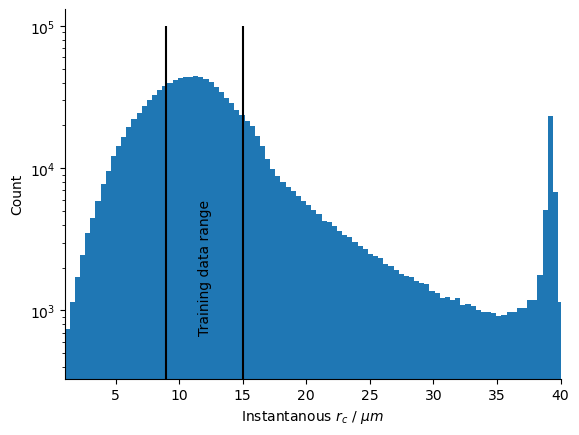

In [47]:
radius = mass_to_radius(ds["clw/qnc"]) * 1e6


#bins_global = [np.linspace(1, 40, 200), np.linspace(40, 500, 200)]
fig, ax =plt.subplots()

plt.hist(radius.values.flatten(), bins=np.linspace(1,41,100))
ax.set_yscale('log')
#ax.set_xscale("log")
ax.set_xlim(1,40)
sn.despine(fig)
ax.set_xlabel("Instantanous $r_c$ / $\mu m$")
ax.set_ylabel("Count")
ax.vlines(9,0,1e5, color="black")
ax.vlines(15,0,1e5, color="black")
#ax.vlines(40,0,1e8, color="grey")
ax.text(x=11.5, y= 7e2, s="Training data range", rotation="vertical")
#ax.text(x=41, y= 3e1, s="Thershold to rain", rotation="vertical")

fig.savefig("../plots/cloud_radii_instantaneous.png")